# 3. Frozen retrieval: technical development pilot

## 1. Which models and inputs do we compare?

The preceding notebook established provisional map references. Here we test the
connection from **RGB images and query text** to frozen embeddings, complete rankings
and map-agreement metrics. This is development inspection of the unchanged ten-patch
pilot, not a final benchmark. All patches are from one Austria tile. Eight intents
have three formulations each; every formulation is reported separately.

We compare the official OpenAI CLIP and RemoteCLIP **ViT-B/32** checkpoints. Both
produce 512-dimensional representations. RemoteCLIP uses QuickGELU following its
official retrieval recipe (initializing the OpenAI architecture before loading its
weights). No training, candidate relevance filtering or extra models are used.
[Checkpoint provenance and metric contracts](../docs/RETRIEVAL_PILOT.md) describe
sources, checksums, preprocessing, license information and limitations.

In [1]:
from pathlib import Path
import json
import warnings

# Optional notebook progress widgets are not needed for this bounded pilot.
warnings.filterwarnings("ignore", message="IProgress not found.*")

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from earth_observation.encoding import file_digest, model_rgb
from earth_observation.pilot import run_retrieval_pilot
from earth_observation.raster import RGB_BANDS, patch_files, read_rgb_bands
from earth_observation.reference import evaluate_pilot, load_specifications

# Configuration: development pilot only; no parameter selection from model results.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
CONFIG_PATH = ROOT / "config/frozen-models-v1.json"
CONFIG = json.loads(CONFIG_PATH.read_text())
EXAMPLE_QUERIES = ["single-arable-land/p1", "adjacent-forest-water/p1"]
MODEL_NAMES = {"clip-openai-vit-b32": "CLIP", "remoteclip-vit-b32": "RemoteCLIP"}
MODEL_COLORS = {"clip-openai-vit-b32": "#2166ac", "remoteclip-vit-b32": "#d6604d"}
OUTPUT = ROOT / "outputs" / CONFIG["version"]
plt.rcParams["figure.dpi"] = 80
display(pd.DataFrame(CONFIG["models"])[["model_id", "size_bytes", "sha256"]])
display(pd.Series(CONFIG["runtime"], name="runtime"))

,model_id,size_bytes,sha256
0,clip-openai-vit-b32,353976522,40d365715913c9da98579312b702a82c18be219cc2a734...
1,remoteclip-vit-b32,605208421,60014e395d930a3f2963d1d89c8522bf4ad56775571e43...


device               cpu
precision        float32
torch_threads          4
batch_size             5
seed                   0
Name: runtime, dtype: object

## 2. How do measurements become embeddings and rankings?

Raw B04/B03/B02 values become RGB uint8 using
$\operatorname{round}_{\mathrm{even}}(255\,\operatorname{clip}(DN/3000,0,1))$.
This is an explicit, versioned development input decision, not calibrated reflectance
and not an implicit call to the display helper. Any masked or nonfinite RGB pixel
rejects the input; the current thirty bands have no masked pixels. No map-based
mask is applied. Checkpoint preprocessing then resizes the shortest edge to 224
with bicubic interpolation, takes a central 224 × 224 crop, converts to a tensor
and uses CLIP's channel means and standard deviations. Text uses CLIP byte-pair
tokenization with BOS/EOS and a 77-token context; overlong text fails rather than
being silently truncated.

For image embedding $v_i$ and text embedding $t_q$, unit normalization yields
$\hat v_i=v_i/\|v_i\|_2$ and $\hat t_q=t_q/\|t_q\|_2$. The score is
$S_{qi}=\hat t_q^\mathsf{T}\hat v_i$: cosine similarity, **not a probability**.
All 24 × 10 scores per model are computed directly. Ties use ascending full patch
ID. Maps first enter after ranking, to attach reference states.

The cache identifies checkpoint, architecture, RGB conversion, checkpoint
preprocessing, tokenizer bytes, software and source versions, ordered image bytes,
and ordered query IDs/texts. Cached float32 unit vectors carry shape and byte-digest
checks. A cache hit does not instantiate or run the model. The table below distinguishes
original measured encoding times from this notebook's cached execution.

In [2]:
metrics, rankings, provenance = run_retrieval_pilot(ROOT)
runtime_rows = []
for model_id, run in provenance["models"].items():
    original = run["original_encoding"]
    assert original["evaluation_mode"] and original["all_parameters_frozen"]
    runtime_rows.append({"model": MODEL_NAMES[model_id], "cache_hit_now": run["cache_hit"],
                         "load_s_original": original["load_seconds"],
                         "images_s_original": original["image_encoding_seconds"],
                         "texts_s_original": original["text_encoding_seconds"],
                         "lookup_or_encode_s_now": run["cache_lookup_or_encode_seconds"],
                         "rank_s_now": run["ranking_seconds"]})
display(pd.DataFrame(runtime_rows).round(4))
display(pd.Series(provenance["platform"], name="actual_runtime"))
print(f"{len(metrics)} formulation results; {len(rankings)} scored candidates.")

,model,cache_hit_now,load_s_original,images_s_original,texts_s_original,lookup_or_encode_s_now,rank_s_now
0,CLIP,True,1.6570,0.2046,0.9478,0.0009,0.0002
1,RemoteCLIP,True,1.8004,0.1800,0.9608,0.0007,0.0002


machine      arm64
python     3.12.12
system      Darwin
Name: actual_runtime, dtype: object

48 formulation results; 480 scored candidates.


### 2.1 Does a second run reuse the same embeddings?

Check cache hits, unchanged cache modification times and exactly equal result tables.
This checks reuse without running inference again, including on a fresh checkout
where the preceding cell initially creates embeddings.

In [3]:
cache_files = [ROOT / "data/cache/embeddings" / f"{run['cache_key']}.npz"
               for run in provenance["models"].values()]
mtimes = [path.stat().st_mtime_ns for path in cache_files]
reused_metrics, reused_rankings, reused_provenance = run_retrieval_pilot(ROOT)
assert all(run["cache_hit"] for run in reused_provenance["models"].values())
assert mtimes == [path.stat().st_mtime_ns for path in cache_files]
pd.testing.assert_frame_equal(metrics, reused_metrics)
pd.testing.assert_frame_equal(rankings, reused_rankings)
print("Both embedding caches reused; no encoding; unchanged files and identical results.")

Both embedding caches reused; no encoding; unchanged files and identical results.


## 3. What do P@10 and average precision measure?

For fully judged candidates, let $r_j\in\{0,1\}$ indicate map relevance at rank
$j$, and $R=\sum_{j=1}^{N}r_j$. We define

$$P@10=\frac{1}{10}\sum_{j=1}^{10}r_j,\qquad
AP=\frac{1}{R}\sum_{j=1}^{N}r_j\frac{\sum_{\ell=1}^{j}r_\ell}{j}.$$

AP averages precision at relevant ranks and rewards earlier relevant images.
P@10 is undefined with fewer than ten candidates. AP is undefined with zero
positives; P@10 is zero for ten or more fully judged negative candidates. Any
unknown reference makes the main metrics undefined under our conservative policy.
We retain counts and judged coverage. Separately named `judged_only_*` diagnostics
remove unknowns from the already fixed ranking; diagnostic precision divides by
min(10, judged count). These are not unrestricted main retrieval metrics.

With **exactly ten candidates**, P@10 equals reference prevalence and cannot
measure ranking quality. All candidates here are judged; forest AP = 1 is also
uninformative because all ten patches are forest-positive. No intent aggregation
or statistical interval is computed.

In [4]:
first_formulation = metrics[metrics.query_id.str.endswith("/p1")]
ap_table = first_formulation.pivot(index="intent_id", columns="model_id",
                                   values="average_precision").rename(columns=MODEL_NAMES)
coverage = first_formulation[first_formulation.model_id == "clip-openai-vit-b32"].set_index("intent_id")
display(coverage[["candidate_count", "known_positive_count", "unknown_count", "p_at_10"]]
        .join(ap_table).round(4))

,candidate_count,known_positive_count,unknown_count,p_at_10,CLIP,RemoteCLIP
intent_id,,,,,,
single-forest,10,10,0,1.0,1.0000,1.0000
single-inland-water,10,6,0,0.6,0.6607,0.8179
single-arable-land,10,3,0,0.3,0.8095,0.3417
single-pasture,10,5,0,0.5,0.4635,0.5976
both-forest-water,10,6,0,0.6,0.7440,0.8179
adjacent-forest-water,10,6,0,0.6,0.6357,0.7345
both-arable-pasture,10,2,0,0.2,0.4167,0.2500
adjacent-arable-pasture,10,2,0,0.2,0.3667,0.2083


## 4. How do individual formulations behave?

The first-formulation table is a display slice, not an average across paraphrases.
For example, CLIP has AP 0.8095 and RemoteCLIP 0.3417 for the first arable-land
formulation; for the first inland-water formulation their AP values are 0.6607
and 0.8179. This motivates inspecting ranks, not declaring an overall winner.
The complete table below keeps all formulations separate. Query wording and
reference thresholds were inherited unchanged, not selected from these scores.

In [5]:
display(metrics.pivot(index="query_id", columns="model_id", values="average_precision")
        .rename(columns=MODEL_NAMES).round(4))

model_id,CLIP,RemoteCLIP
query_id,,
adjacent-arable-pasture/p1,0.3667,0.2083
adjacent-arable-pasture/p2,0.5000,0.2083
adjacent-arable-pasture/p3,0.4500,0.2250
adjacent-forest-water/p1,0.6357,0.7345
adjacent-forest-water/p2,0.8107,0.7028
adjacent-forest-water/p3,0.8375,0.8972
both-arable-pasture/p1,0.4167,0.2500
both-arable-pasture/p2,0.4167,0.2250
both-arable-pasture/p3,0.4500,0.2250


## 5. Which actual top images explain the scores?

Inspect the first three ranks for two fixed first formulations: arable land and
forest adjacent to inland water, for both models. Every row uses the same
unrestricted ten candidates. Titles show cosine similarity and the provisional
**map** decision. These labels are added after ranking and are not visually
verified truth. The displayed images use the explicit model RGB conversion before
checkpoint resizing. Brightness/color alone is not a land-cover reference.
No separate relation-control candidate set is tested in this package.

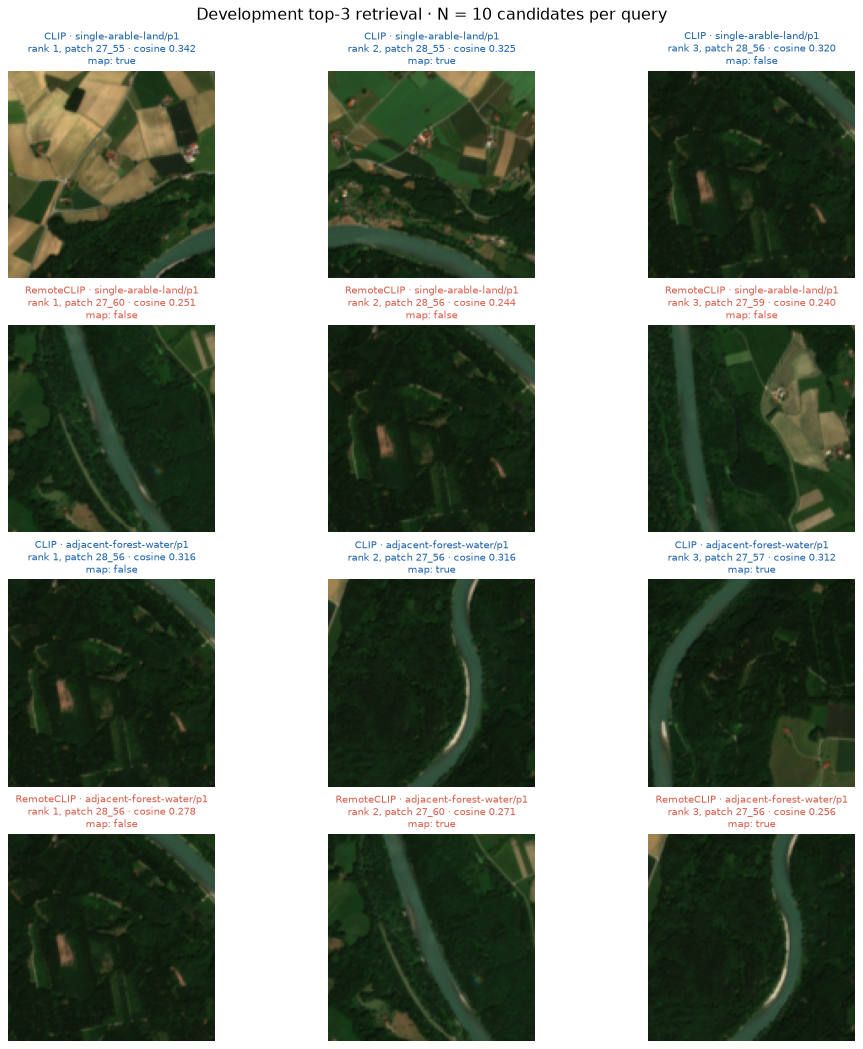

,model,query_id,rank,patch_suffix,map_state
0,CLIP,single-arable-land/p1,1,27_55,true
1,CLIP,single-arable-land/p1,2,28_55,true
2,CLIP,single-arable-land/p1,3,28_56,false
3,RemoteCLIP,single-arable-land/p1,1,27_60,false
4,RemoteCLIP,single-arable-land/p1,2,28_56,false
5,RemoteCLIP,single-arable-land/p1,3,27_59,false
6,CLIP,adjacent-forest-water/p1,1,28_56,false
7,CLIP,adjacent-forest-water/p1,2,27_56,true
8,CLIP,adjacent-forest-water/p1,3,27_57,true
9,RemoteCLIP,adjacent-forest-water/p1,1,28_56,false


In [6]:
fig, axes = plt.subplots(4, 3, figsize=(12, 13), constrained_layout=True)
example_table = []
row_number = 0
for query_id in EXAMPLE_QUERIES:
    for model_id in MODEL_NAMES:
        top = rankings[(rankings.query_id == query_id) & (rankings.model_id == model_id)].head(3)
        for column, result in enumerate(top.itertuples()):
            paths = patch_files(result.patch_id, ROOT / "data/raw/BigEarthNet-S2",
                                ROOT / "data/raw/Reference_Maps")
            image = model_rgb(read_rgb_bands({b: paths[b] for b in RGB_BANDS}),
                              CONFIG["rgb"]["upper_dn"])
            axes[row_number, column].imshow(image)
            suffix = "_".join(result.patch_id.split("_")[-2:])
            axes[row_number, column].set_title(
                f"{MODEL_NAMES[model_id]} · {query_id}\n"
                f"rank {result.rank}, patch {suffix} · cosine {result.cosine_similarity:.3f}\n"
                f"map: {result.reference_state}", color=MODEL_COLORS[model_id], fontsize=9)
            axes[row_number, column].axis("off")
            example_table.append({"model": MODEL_NAMES[model_id], "query_id": query_id,
                                  "rank": result.rank, "patch_suffix": suffix,
                                  "map_state": result.reference_state})
        row_number += 1
fig.suptitle("Development top-3 retrieval · N = 10 candidates per query", fontsize=14)
figure_path = OUTPUT / "top_results.png"
fig.savefig(figure_path, dpi=140)
plt.show()
display(pd.DataFrame(example_table))

### 5.1 Why is the visually water-containing top result map-negative?

Both models rank patch `28_56` first for the illustrated forest/water adjacency
query. RGB inspection shows forest and a water strip. The native map has 4.53%
inland water, below the unchanged 5% presence threshold, despite 880 m of shared
forest/water boundary. The derived adjacency condition therefore fails its water
presence requirement. This is disagreement with the operational reference, not
proof that the natural-language spatial description is visually wrong. We retain
the rule and do not retune it from these model results.

In [7]:
rules, queries = load_specifications(ROOT / "config/reference-rules-v1.json",
                                    ROOT / "config/query-specification-v1.json")
summaries, _ = evaluate_pilot(ROOT / "manifests/data-pilot-v1.json", ROOT / "data/cache",
                            ROOT / "data/raw", rules, queries)
patch_id = next(pid for pid in summaries if pid.endswith("_28_56"))
evidence = summaries[patch_id]
display(pd.Series({"map_water_percent": 100 * evidence["classes"]["inland_water"]["fraction_lower"],
                   "required_water_percent": 100 * rules["classes"]["inland_water"]["presence_fraction"],
                   "map_forest_water_boundary_m": evidence["pairs"][("forest", "inland_water")]["boundary_lower_m"],
                   "required_boundary_m": rules["adjacency"]["min_shared_boundary_m"]}).round(4))

map_water_percent                4.5278
required_water_percent           5.0000
map_forest_water_boundary_m    880.0000
required_boundary_m             60.0000
dtype: float64

## 6. Findings, limitations and next stage

Both identified frozen models produce valid embeddings, complete deterministic
rankings and per-formulation map-agreement metrics. Cache reuse is verified above.
The selected arable examples show that similarity ranking can put map-negative
images before positives; apparent color/texture plausibility does not establish
map agreement. The forest/water examples provide successes as well as disagreement
with the provisional map condition; neither map labels nor RGB inspection establish
precise boundary truth.

The ten nearby patches lack forest negatives and both-present/nonadjacent cases.
Conjunction and adjacency reference sets coincide for each pair. Differences in
their AP values therefore reflect different text rankings of the same reference
set and cannot isolate relation understanding. P@10 is prevalence here. These are
technical development results without uncertainty estimates or final performance
claims. We do not retune queries, preprocessing or thresholds from them.

Saved locally: checkpoint weights; content-identified image/text embeddings;
`metrics.csv`, `rankings.csv`, `run.json` and the illustrated top results under the
experiment version. Reusable encoding/cache/ranking/metric logic is in `src`;
small tables and this exploratory figure remain here. The next stage is broader
reference coverage analysis and an explicit benchmark freeze, before final testing.

In [8]:
figure_provenance = {"experiment_version": CONFIG["version"],
                     "example_queries": EXAMPLE_QUERIES,
                     "figure_sha256": file_digest(figure_path),
                     "ranking_sha256": reused_provenance["outputs"]["rankings.csv"],
                     "embedding_cache_keys": [r["cache_key"] for r in provenance["models"].values()]}
(OUTPUT / "top_results_provenance.json").write_text(json.dumps(figure_provenance, indent=2) + "\n")
print("Saved versioned development tables, run provenance and top-result figure.")

Saved versioned development tables, run provenance and top-result figure.
